# Vision — Deteksi Objek dengan Kelas Soal (fine-tune YOLOv8n)
**Kapan dipakai:** soal memberi gambar + kotak berlabel (bounding box), dan meminta kotak di
gambar test. Contoh: cari strip tanggal di label obat, plat nomor, cacat produk.

**Langkah:** baca anotasi COCO → susun folder YOLO (`images/`, `labels/`, `data.yaml`) dengan
split train/val → fine-tune YOLOv8n → mAP di val → prediksi test → lihat kasus paling ragu →
simpan kotak + potongan gambar untuk tahap berikutnya (misalnya OCR).

**Input yang diharapkan:** satu folder gambar train + satu file COCO JSON. Soal memberi YOLO
`.txt` atau VOC `.xml`? Ubah dulu jadi tabel dengan `vision/konversi_anotasi`, atau langsung
pakai folder YOLO yang sudah ada (lihat sel "Susun folder YOLO").

**Data demo:** `vignette` (label harga obat). Train = 750 foto rata dari ekspor Roboflow,
kelas `entete` (strip LOT/FAB/EXP) dan `vin` (seluruh stiker). Test = 674 foto **tanpa kotak**,
banyak yang miring/terbalik/dipegang tangan. Jadi mAP val (dari train) terlalu optimistis untuk
test; selalu lihat grid prediksi test.

In [1]:
import glob
import json
import os
import shutil

import matplotlib.pyplot as plt
import pandas as pd
import torch
from matplotlib.patches import Rectangle
from PIL import Image
from sklearn.model_selection import train_test_split
from ultralytics import YOLO

## Konfigurasi
`CLASS_NAMES` = kelas soal, urutannya menjadi nomor kelas YOLO. Kelas COCO dicocokkan lewat nama.

In [2]:
DATA_FOLDER = "../../../data_latihan/vision/vignette"   # GANTI saat lomba
TRAIN_FOLDER = f"{DATA_FOLDER}/train"
COCO_FILE = f"{TRAIN_FOLDER}/_annotations.coco.json"
TEST_FOLDER = f"{DATA_FOLDER}/test"
IMAGE_EXTENSION = ".jpg"
CLASS_NAMES = ["entete", "vin"]       # GANTI: nama kelas persis seperti di anotasi
TARGET_CLASS = "entete"               # kelas yang dipotong untuk tahap berikutnya
WEIGHTS = "../../../pretrained/yolov8n/yolov8n.pt"

# semua hasil ke luar folder repo (JANGAN diarahkan ke folder data soal)
OUTPUT_FOLDER = "../../../outputs/vision/deteksi"
DATASET_FOLDER = f"{OUTPUT_FOLDER}/dataset_yolo"     # dibuat ulang setiap Run All
CROP_FOLDER = f"{OUTPUT_FOLDER}/potongan"
RUNS_FOLDER = os.path.abspath(f"{OUTPUT_FOLDER}/runs")   # ultralytics butuh path lengkap
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

VAL_FRACTION = 0.2
EPOCHS = 30
IMAGE_SIZE = 416       # samakan dengan ukuran gambar soal (lebih besar = lebih lambat)
BATCH_SIZE = 16        # kehabisan memori GPU? turunkan ke 8 atau 4
MIN_CONFIDENCE = 0.1
MARGIN = 0.05          # tepi tambahan di sekitar potongan (5% lebar/tinggi kotak)
SEED = 42
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = 0

## Baca anotasi COCO → tabel piksel
`bbox` COCO = `[kiri, atas, lebar, tinggi]` dalam piksel.

In [3]:
with open(COCO_FILE) as file:
    coco = json.load(file)
print("categories:", coco["categories"])

category_names = {}
for category in coco["categories"]:
    category_names[category["id"]] = category["name"]
image_info = {}
for item in coco["images"]:
    image_info[item["id"]] = item

rows = []
for annotation in coco["annotations"]:
    info = image_info[annotation["image_id"]]
    left, top, box_width, box_height = annotation["bbox"]
    rows.append([info["file_name"], info["width"], info["height"],
                 category_names[annotation["category_id"]], left, top, box_width, box_height])
boxes = pd.DataFrame(rows, columns=["image", "width", "height", "class_name",
                                    "left", "top", "box_width", "box_height"])
print(boxes.shape)
print(boxes["class_name"].value_counts())

categories: [{'id': 0, 'name': 'Images', 'supercategory': 'none'}, {'id': 1, 'name': 'entete', 'supercategory': 'Images'}, {'id': 2, 'name': 'vin', 'supercategory': 'Images'}]
(1509, 8)
class_name
vin       755
entete    754
Name: count, dtype: int64


## EDA singkat: ukuran dan bentuk kotak per kelas
Rasio lebar/tinggi < 1 = kotak tegak. Di demo, semua `entete` di train tegak, padahal di test
ada yang mendatar. Detektor tidak akan bisa menemukan bentuk yang tidak pernah dilihatnya.

In [4]:
boxes["ratio_w_h"] = boxes["box_width"] / boxes["box_height"]
image_area = boxes["width"] * boxes["height"]
boxes["area_fraction"] = boxes["box_width"] * boxes["box_height"] / image_area
summary = boxes.groupby("class_name")[["ratio_w_h", "area_fraction"]].describe()
print(summary.round(2).T)
boxes_per_image = boxes.groupby("image").size()
print("kotak per gambar:", boxes_per_image.value_counts().to_dict())

class_name           entete     vin
ratio_w_h     count  754.00  755.00
              mean     0.36    1.51
              std      0.08    0.07
              min      0.20    1.34
              25%      0.32    1.47
              50%      0.34    1.50
              75%      0.38    1.54
              max      0.64    1.83
area_fraction count  754.00  755.00
              mean     0.07    0.39
              std      0.02    0.02
              min      0.03    0.30
              25%      0.06    0.37
              50%      0.07    0.39
              75%      0.08    0.40
              max      0.11    0.44
kotak per gambar: {2: 741, 3: 9}


## Susun folder YOLO: `images/train`, `images/val`, `labels/train`, `labels/val`, `data.yaml`
Split per **gambar** (bukan per kotak), supaya kotak dari satu gambar tidak ada di train dan val.
Soal sudah memberi folder YOLO lengkap? Lewati sel ini, isi `DATASET_FOLDER` dengan folder itu,
dan pastikan `data.yaml` berisi `path` lengkap, `train`, `val`, dan `names`.

In [5]:
shutil.rmtree(DATASET_FOLDER, ignore_errors=True)       # mulai dari folder kosong
image_names = []
for item in coco["images"]:
    image_names.append(item["file_name"])
train_names, val_names = train_test_split(image_names, test_size=VAL_FRACTION, random_state=SEED)

for part, names in [("train", train_names), ("val", val_names)]:
    os.makedirs(f"{DATASET_FOLDER}/images/{part}")
    os.makedirs(f"{DATASET_FOLDER}/labels/{part}")
    for name in names:
        shutil.copy(f"{TRAIN_FOLDER}/{name}", f"{DATASET_FOLDER}/images/{part}")
        lines = []
        for box in boxes[boxes["image"] == name].itertuples():
            cx = (box.left + box.box_width / 2) / box.width
            cy = (box.top + box.box_height / 2) / box.height
            class_id = CLASS_NAMES.index(box.class_name)
            lines.append(f"{class_id} {cx:.6f} {cy:.6f} {box.box_width / box.width:.6f} "
                         f"{box.box_height / box.height:.6f}")
        stem = os.path.splitext(name)[0]
        with open(f"{DATASET_FOLDER}/labels/{part}/{stem}.txt", "w") as file:
            file.write("\n".join(lines))

dataset_path = os.path.abspath(DATASET_FOLDER).replace("\\", "/")   # YOLO butuh path lengkap
yaml_text = f"path: {dataset_path}\ntrain: images/train\nval: images/val\nnames:\n"
for class_id in range(len(CLASS_NAMES)):
    yaml_text = yaml_text + f"  {class_id}: {CLASS_NAMES[class_id]}\n"
with open(f"{DATASET_FOLDER}/data.yaml", "w") as file:
    file.write(yaml_text)
print(yaml_text)
print("train:", len(train_names), "| val:", len(val_names))

path: Z:/GEMASTIK/Vignate-GEMASTIK/outputs/vision/deteksi/dataset_yolo
train: images/train
val: images/val
names:
  0: entete
  1: vin

train: 600 | val: 150


## Fine-tune YOLOv8n
Bobot pretrained COCO hanya titik awal; kelas soal dipelajari dari nol di lapisan akhir.
Train vignette selalu tegak, test banyak yang miring/terbalik. Karena itu dipakai augmentasi
rotasi: `degrees` = putar acak ±derajat, `flipud` = peluang dibalik atas-bawah.
Hasil di data demo: tanpa augmentasi 50 gambar test tanpa entete, `degrees=90` 12,
`degrees=180, flipud=0.5` 5. mAP val sedikit turun (val tegak semua), tetapi test jauh lebih baik.
Test setegak train? Pakai baris alternatif tanpa augmentasi rotasi.

In [6]:
model = YOLO(WEIGHTS)
model.train(data=f"{DATASET_FOLDER}/data.yaml", epochs=EPOCHS, imgsz=IMAGE_SIZE, batch=BATCH_SIZE,
            workers=0, device=DEVICE, project=RUNS_FOLDER, name="train", exist_ok=True, plots=False,
            seed=SEED, verbose=False, degrees=180, flipud=0.5)
# model.train(data=f"{DATASET_FOLDER}/data.yaml", epochs=EPOCHS, imgsz=IMAGE_SIZE,
#             batch=BATCH_SIZE, workers=0, device=DEVICE, project=RUNS_FOLDER, name="train",
#             exist_ok=True, plots=False, seed=SEED, verbose=False)   # tanpa rotasi

New https://pypi.org/project/ultralytics/8.4.184 available  Update with 'pip install -U ultralytics'


Ultralytics 8.4.172  Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=../../../outputs/vision/deteksi/dataset_yolo/data.yaml, degrees=180, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=../../../pretrained/yolov8n/yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, pat

Overriding model.yaml nc=80 with nc=2



                   from  n    params  module                                       arguments                     


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 80% ━━━━━━━━━╸── 4/5 4.0it/s 0.8s<0.2s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 5.5it/s 0.9s

                   all        150        302       0.99      0.977      0.992      0.826


Speed: 0.1ms preprocess, 0.6ms inference, 0.0ms loss, 1.4ms postprocess per image


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x0000017D20511320>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.0

## Evaluasi di val
mAP50 = ketepatan kotak bila "kena" cukup dengan IoU ≥ 0.5. mAP50-95 lebih ketat.

In [7]:
model = YOLO(model.trainer.best)        # bobot terbaik hasil latih
metrics = model.val(data=f"{DATASET_FOLDER}/data.yaml", imgsz=IMAGE_SIZE, batch=BATCH_SIZE,
                    workers=0, device=DEVICE, project=RUNS_FOLDER, name="val", exist_ok=True,
                    plots=False, verbose=False)
print("mAP50:", round(metrics.box.map50, 4), "| mAP50-95:", round(metrics.box.map, 4))
for class_id in range(len(CLASS_NAMES)):
    print(CLASS_NAMES[class_id], "mAP50:", round(metrics.box.ap50[class_id], 4))

Ultralytics 8.4.172  Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)


Model summary (fused): 72 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs


val: Fast image access  (ping: 0.00.0 ms, read: 195.840.1 MB/s, size: 21.3 KB)


val: Scanning Z:\GEMASTIK\Vignate-GEMASTIK\outputs\vision\deteksi\dataset_yolo\labels\val.cache... 150 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 48.4Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 10% ━─────────── 1/10 2.0it/s 0.1s<4.4s

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 90% ━━━━━━━━━━╸─ 9/10 8.6it/s 0.9s<0.1s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 10.1it/s 1.0s

                   all        150        302       0.99      0.977      0.992      0.826


Speed: 0.1ms preprocess, 1.4ms inference, 0.0ms loss, 1.2ms postprocess per image


mAP50: 0.9921 | mAP50-95: 0.8259
entete mAP50: 0.9893
vin mAP50: 0.995


## Prediksi test: satu kotak `TARGET_CLASS` dengan keyakinan tertinggi per gambar
`stream=True` = gambar diproses satu per satu, jadi ribuan gambar tidak memenuhi memori GPU.

In [8]:
test_paths = sorted(glob.glob(f"{TEST_FOLDER}/*{IMAGE_EXTENSION}"))
target_id = CLASS_NAMES.index(TARGET_CLASS)
results = model.predict(test_paths, imgsz=IMAGE_SIZE, conf=MIN_CONFIDENCE, stream=True,
                        verbose=False, device=DEVICE)
rows = []
for image_path, result in zip(test_paths, results):
    best = [os.path.basename(image_path), 0.0, 0, 0, 0, 0]
    for number in range(len(result.boxes)):
        confidence = float(result.boxes.conf[number])
        if int(result.boxes.cls[number]) == target_id and confidence > best[1]:
            left, top, right, bottom = result.boxes.xyxy[number].tolist()
            best = [best[0], confidence, left, top, right, bottom]
    rows.append(best)
predictions = pd.DataFrame(rows, columns=["id", "confidence", "x1", "y1", "x2", "y2"])
print("gambar test:", len(predictions))
print("tanpa", TARGET_CLASS, "terdeteksi:", (predictions["confidence"] == 0).sum())
predictions["confidence"].describe()

gambar test: 674
tanpa entete terdeteksi: 5


count    674.000000
mean       0.751876
std        0.161493
min        0.000000
25%        0.701581
50%        0.796524
75%        0.857999
max        0.947089
Name: confidence, dtype: float64

## Lihat 8 prediksi test paling ragu
Di sinilah kelemahan detektor terlihat (gambar miring, terbalik, kotak salah tempat).

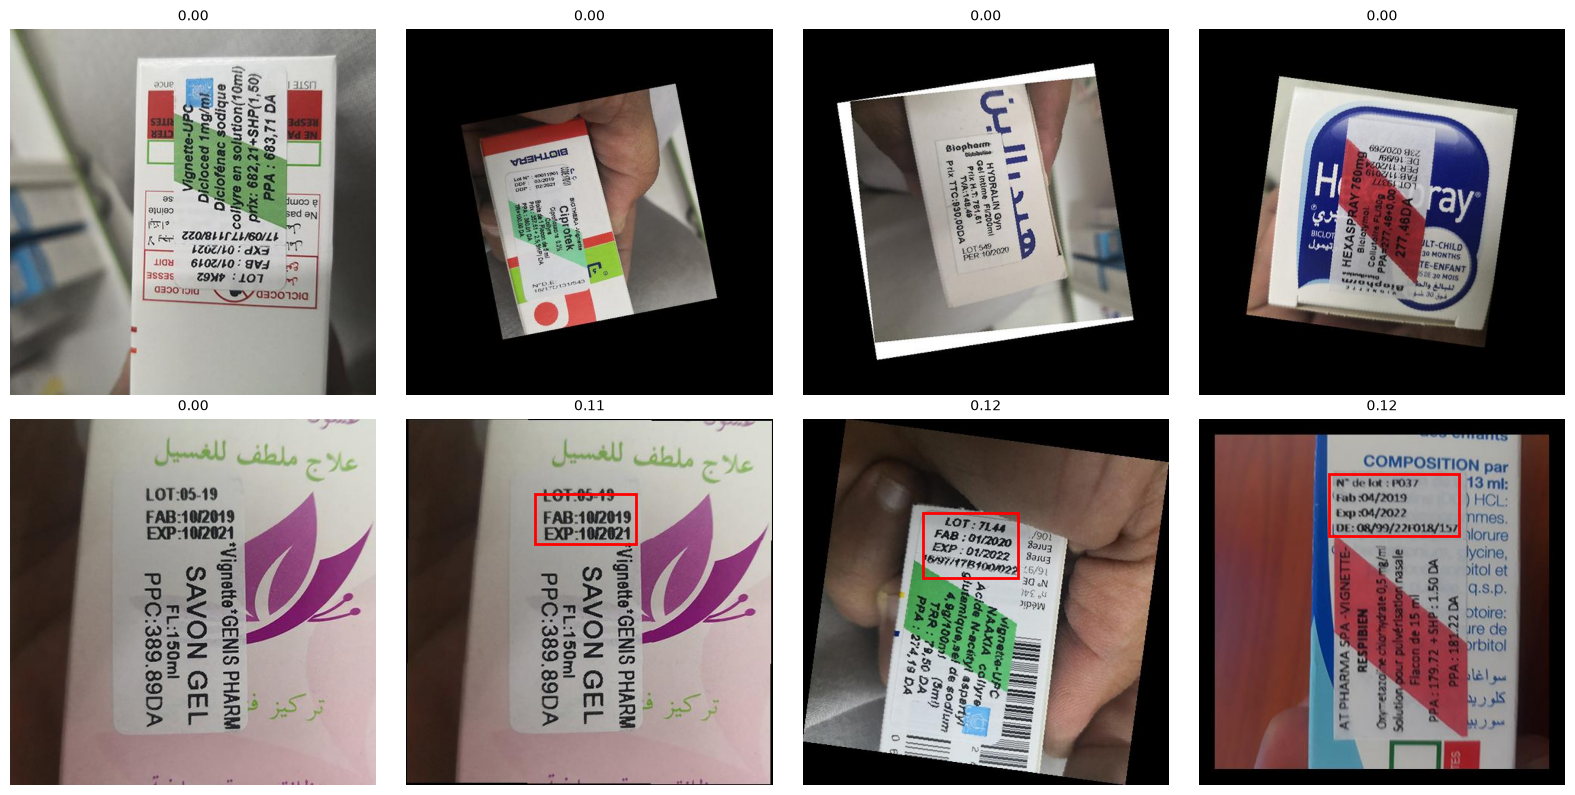

In [9]:
doubtful = predictions.sort_values("confidence").head(8)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, row in zip(axes.ravel(), doubtful.itertuples()):
    ax.imshow(Image.open(f"{TEST_FOLDER}/{row.id}"))
    ax.add_patch(Rectangle((row.x1, row.y1), row.x2 - row.x1, row.y2 - row.y1,
                           fill=False, color="red", lw=2))
    ax.set_title(f"{row.confidence:.2f}", fontsize=10)
    ax.axis("off")
plt.tight_layout()
fig.savefig(f"{OUTPUT_FOLDER}/prediksi_ragu.png", dpi=80)
plt.show()

## Simpan kotak + potongan gambar
Potongan diberi sedikit tepi (`MARGIN`) supaya huruf di pinggir tidak terpotong.
`<OUTPUT_FOLDER>/potongan/<id>` siap dipakai tahap berikutnya, misalnya OCR.

In [10]:
shutil.rmtree(CROP_FOLDER, ignore_errors=True)
os.makedirs(CROP_FOLDER)
for row in predictions[predictions["confidence"] > 0].itertuples():
    image = Image.open(f"{TEST_FOLDER}/{row.id}")
    margin_x = (row.x2 - row.x1) * MARGIN
    margin_y = (row.y2 - row.y1) * MARGIN
    crop = image.crop((max(row.x1 - margin_x, 0), max(row.y1 - margin_y, 0),
                       min(row.x2 + margin_x, image.width), min(row.y2 + margin_y, image.height)))
    crop.save(f"{CROP_FOLDER}/{row.id}")
print("potongan disimpan:", len(os.listdir(CROP_FOLDER)))

predictions.to_csv(f"{OUTPUT_FOLDER}/hasil_deteksi.csv", index=False)
predictions.head()

potongan disimpan: 669


,id,confidence,x1,y1,x2,y2
0,0016f1ad9e7f16aa6dd2b8c9c13cb922.jpg,0.759621,140.761642,248.354752,208.679260,365.375275
1,005e28f75a93bc4de0e9e11373bdca47.jpg,0.768012,117.858231,250.500732,154.963882,358.786072
2,007f7b00eb0a66cabcd72007358e3660.jpg,0.120840,176.621964,138.455750,317.129181,234.012405
3,009a43c2870949af417f769b90ee20cf.jpg,0.857892,65.285896,230.370041,147.275879,409.669891
4,014d3d8a2ef0d4deb88a83357781745c.jpg,0.769983,168.251770,247.489365,231.301956,353.437225


## Masalah umum
- **`CUDA out of memory`:** turunkan `BATCH_SIZE` (8 → 4) atau `IMAGE_SIZE`.
- **mAP val tinggi tapi test buruk:** train dan test berbeda (sudut, pencahayaan). Lihat grid
  prediksi ragu, lalu tambah augmentasi (`degrees`, `flipud`, `hsv_v`) atau data yang mirip test.
- **Kelas tertukar:** urutan `CLASS_NAMES` harus sama dengan `names` di `data.yaml`.
- **`No labels found`:** folder `labels/` harus sejajar `images/`, nama `.txt` = nama gambar.
- **Format label 9 angka per baris:** itu OBB/polygon; ekspor ulang sebagai deteksi.